# Chathouse: Data Transformation and Exploratory Data Analysis

This notebook turns raw WildChat-1M conversation logs into silver and gold tables, checks their quality and explores user activity, model mix and engagement. It reads every Parquet file that matches `CHATHOUSE_DATA_GLOB`. Gold tables go to `output/gold`.

Source: Allen Institute for AI, WildChat-1M, Hugging Face dataset `allenai/WildChat-1M` (ODC-BY 1.0).

# 1. Setup and data load

In [1]:
import glob
import os
import warnings
from pathlib import Path

import duckdb
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.options.display.float_format = lambda v: f"{v:,.3f}"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_GLOB = os.environ.get("CHATHOUSE_DATA_GLOB", str(ROOT / "*.parquet"))
OUT_DIR = ROOT / "output" / "gold"
OUT_DIR.mkdir(parents=True, exist_ok=True)
HEAVY_IP_MIN_CONVS = 100

NAVY, BLUE, RED, GREY, INK = "#14213D", "#2A78D6", "#D7263D", "#9CA3AF", "#1F2937"

con = duckdb.connect()
con.execute("SET TimeZone='UTC'")

def sql(query):
    return con.sql(query).df()

def md(text):
    display(Markdown(text))

def n(v):
    return f"{int(v):,}"

def pct(v, d=1):
    return f"{100 * v:.{d}f}%"

def style(fig, title, height=440, xtitle=None, ytitle=None):
    fig.update_layout(template="plotly_white", title=dict(text=title, x=0, font=dict(size=16, color=NAVY)),
                      width=980, height=height, margin=dict(l=70, r=30, t=70, b=60),
                      font=dict(family="Arial", size=13, color=INK), legend=dict(orientation="h", y=1.12, x=0))
    fig.update_xaxes(title=xtitle, showgrid=False)
    fig.update_yaxes(title=ytitle, gridcolor="#E5E7EB", zeroline=False)
    return fig

files = sorted(glob.glob(DATA_GLOB))
assert files, "No Parquet files match the data path"
con.execute(f"create or replace view bronze as select * from read_parquet({files!r}, filename=true)")

inventory = sql("select regexp_extract(filename, '[^/]+$') as file, count(*) as conversations from bronze group by 1 order by 1")
inventory["size_mb"] = [os.path.getsize(f) / 1e6 for f in sorted(files, key=os.path.basename)]
display(inventory)
display(sql("""
    select count(*) as conversations, count(distinct hashed_ip) as hashed_ips,
           min(timestamp) as first_timestamp_utc, max(timestamp) as last_timestamp_utc
    from bronze"""))

,file,conversations,size_mb
0,train-00000-of-00014.parquet,59857,230.786


,conversations,hashed_ips,first_timestamp_utc,last_timestamp_utc
0,59857,13908,2023-04-09 00:02:53+00:00,2023-05-04 07:49:52+00:00


# 2. Schema and completeness

In [2]:
schema = sql("describe bronze")[["column_name", "column_type"]]
schema = schema[schema.column_name != "filename"].reset_index(drop=True)
schema["column_type"] = schema.column_type.str.slice(0, 52)
cols = [c for c in schema.column_name if c != "filename"]
null_rate = sql("select " + ", ".join(f'avg(("{c}" is null)::int) as "{c}"' for c in cols) + " from bronze").T
null_rate.columns = ["null_rate"]
display(schema.merge(null_rate, left_on="column_name", right_index=True, how="left"))

,column_name,column_type,null_rate
0,conversation_hash,VARCHAR,0.000
1,model,VARCHAR,0.000
2,timestamp,TIMESTAMP WITH TIME ZONE,0.000
3,conversation,"STRUCT(""content"" VARCHAR, country VARCHAR, has...",0.000
4,turn,BIGINT,0.000
5,language,VARCHAR,0.000
6,openai_moderation,"STRUCT(categories STRUCT(harassment BOOLEAN, ""...",0.000
7,detoxify_moderation,"STRUCT(identity_attack DOUBLE, insult DOUBLE, ...",0.000
8,toxic,BOOLEAN,0.000
9,redacted,BOOLEAN,0.000


# 3. Bronze to silver transformation

In [3]:
con.execute("""
create or replace view stg_conversations as
select conversation[1].turn_identifier as conversation_id,
       conversation_hash, model, timestamp as ts_utc, cast(timestamp as date) as event_date,
       turn, language,
       coalesce(country, 'Unknown') as country,
       coalesce(state, 'Unknown') as state,
       hashed_ip,
       header."user-agent" as user_agent,
       toxic, redacted,
       len(conversation) as utterance_count,
       coalesce(trim(conversation[1].content), '') = '' as empty_first_input,
       len(list_filter(openai_moderation, lambda m: m.flagged)) > 0 as moderation_flagged,
       list_max(list_transform(detoxify_moderation, lambda d: d.toxicity)) as max_toxicity
from bronze
""")

con.execute(f"""
create or replace table dim_user_proxy as
select hashed_ip,
       count(*) as conversations,
       min(ts_utc) as first_seen_utc,
       max(ts_utc) as last_seen_utc,
       min(event_date) as first_seen_date,
       count(*) >= {HEAVY_IP_MIN_CONVS} as is_heavy_ip
from stg_conversations
where not empty_first_input
group by hashed_ip
""")

con.execute("""
create or replace table silver_conversations as
select s.*, coalesce(d.is_heavy_ip, false) as is_heavy_ip
from stg_conversations s
left join dim_user_proxy d using (hashed_ip)
""")

con.execute("""
create or replace table silver_utterances as
select x.*, c.model
from (
    select cid as conversation_id, u.turn_identifier, u.role, u.language,
           u.toxic, u.redacted, u.timestamp as ts_utc, u.hashed_ip,
           coalesce(u.country, 'Unknown') as country,
           len(u.content) as char_len,
           len(string_split(trim(u.content), ' ')) as word_count,
           coalesce(trim(u.content), '') = '' as is_empty
    from (select conversation[1].turn_identifier as cid, unnest(conversation) as u from bronze)
) x
left join silver_conversations c on c.conversation_id = x.conversation_id
""")

con.execute("create or replace view valid_conversations as select * from silver_conversations where not empty_first_input")

reconciliation = sql("""
select (select count(*) from bronze) as bronze_conversations,
       (select count(*) from silver_conversations) as silver_conversations,
       (select sum(len(conversation))::bigint from bronze) as bronze_utterances,
       (select count(*) from silver_utterances) as silver_utterances,
       (select count(*) from dim_user_proxy) as user_proxy_rows
""")
reconciliation["conversation_rows_match"] = reconciliation.bronze_conversations == reconciliation.silver_conversations
reconciliation["utterance_rows_match"] = reconciliation.bronze_utterances == reconciliation.silver_utterances
display(reconciliation)
display(sql("select * from silver_conversations limit 5"))

,bronze_conversations,silver_conversations,bronze_utterances,silver_utterances,user_proxy_rows,conversation_rows_match,utterance_rows_match
0,59857,59857,344836,344836,13757,True,True


,conversation_id,conversation_hash,model,ts_utc,event_date,turn,language,country,state,hashed_ip,user_agent,toxic,redacted,utterance_count,empty_first_input,moderation_flagged,max_toxicity,is_heavy_ip
0,105235,fea746fafe1da19fb7f06418d97cfa7e,gpt-3.5-turbo-0301,2023-04-09 12:59:26+00:00,2023-04-09,2,English,United States,Illinois,b2690ce739bc4eaaf8b3862d5a04566dd2859e2e6e804d...,Mozilla/5.0 (Linux; Android 13; SM-A146U) Appl...,False,False,4,False,False,0.006,False
1,105229,0f8d7e21897e849183bf8bf4d830e65c,gpt-3.5-turbo-0301,2023-04-09 12:59:51+00:00,2023-04-09,6,Russian,Russia,Vladimir Oblast,f61b2f597a6e853e404fed33c030792d2cfe7e8852b119...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,False,False,12,False,False,0.003,False
2,105248,39020c712df9609f60e8038651bd328f,gpt-4-0314,2023-04-09 13:01:06+00:00,2023-04-09,1,German,Germany,North Rhine-Westphalia,08454f909c7baa87c485ef7390d950ced498086066c80c...,Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:1...,False,False,2,False,False,0.000,False
3,105251,61a8abbdfb3b0c86b6002d0b94be6955,gpt-4-0314,2023-04-09 13:01:26+00:00,2023-04-09,1,English,Morocco,Casablanca,0bec548aeaa44dc6aba6c926f3533cdf05d65878bc911f...,Mozilla/5.0 (Linux; Android 10; K) AppleWebKit...,False,False,2,False,False,0.000,False
4,104968,d5585f6442a8a73fd71632581bc95915,gpt-4-0314,2023-04-09 13:02:00+00:00,2023-04-09,2,Indonesian,Indonesia,West Java,e63279eeb18de6d25ee55f6e88d23a3ba97e024363c13d...,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,False,False,4,False,False,0.001,False


# 4. Data quality checks

In [4]:
checks = [
    ("conversation_id is unique and not null", 0.0,
     "select count(*) - count(distinct conversation_id) + count(*) filter (where conversation_id is null) from silver_conversations", "silver_conversations"),
    ("utterance key (conversation_id, turn_identifier, role) is unique", 0.0,
     "select count(*) - count(distinct (conversation_id, turn_identifier, role)) from silver_utterances", "silver_utterances"),
    ("utterance count equals twice the turn count", 0.0,
     "select count(*) filter (where utterance_count != 2 * turn) from silver_conversations", "silver_conversations"),
    ("role is user or assistant", 0.0,
     "select count(*) filter (where role not in ('user', 'assistant')) from silver_utterances", "silver_utterances"),
    ("timestamp is present", 0.0,
     "select count(*) filter (where ts_utc is null) from silver_conversations", "silver_conversations"),
    ("moderation category spellings agree", 0.0,
     """select count(*) filter (where m.categories."self-harm" is distinct from m.categories.self_harm
                                  or m.categories."hate/threatening" is distinct from m.categories.hate_threatening
                                  or m.categories."violence/graphic" is distinct from m.categories.violence_graphic)
        from (select unnest(openai_moderation) as m from bronze)""", "bronze"),
    ("first user input is not empty", 0.02,
     "select count(*) filter (where empty_first_input) from silver_conversations", "silver_conversations"),
    ("conversation_hash is unique", 0.01,
     "select count(*) - count(distinct conversation_hash) from silver_conversations", "silver_conversations"),
    ("country is known", 0.01,
     "select count(*) filter (where country = 'Unknown') from silver_conversations", "silver_conversations"),
    ("state is known", 0.25,
     "select count(*) filter (where state = 'Unknown') from silver_conversations", "silver_conversations"),
    ("user agent is present", 0.05,
     "select count(*) filter (where user_agent is null) from silver_conversations", "silver_conversations"),
]
rows = []
for name, limit, query, table in checks:
    failed = int(con.sql(query).fetchone()[0])
    total = int(con.sql(f"select count(*) from {table}").fetchone()[0])
    share = failed / total if total else 0.0
    rows.append(dict(check=name, rows_failed=failed, share=share, allowed_share=limit, status="PASS" if share <= limit else "FAIL"))
quality = pd.DataFrame(rows)
display(quality)
md(f"{int((quality.status == 'PASS').sum())} of {len(quality)} checks pass. "
   f"Checks that fail: {', '.join(quality.loc[quality.status == 'FAIL', 'check']) or 'none'}.")

,check,rows_failed,share,allowed_share,status
0,conversation_id is unique and not null,0,0.000,0.000,PASS
1,"utterance key (conversation_id, turn_identifie...",0,0.000,0.000,PASS
2,utterance count equals twice the turn count,0,0.000,0.000,PASS
3,role is user or assistant,0,0.000,0.000,PASS
4,timestamp is present,0,0.000,0.000,PASS
5,moderation category spellings agree,0,0.000,0.000,PASS
6,first user input is not empty,471,0.008,0.020,PASS
7,conversation_hash is unique,494,0.008,0.010,PASS
8,country is known,95,0.002,0.010,PASS
9,state is known,10012,0.167,0.250,PASS


11 of 11 checks pass. Checks that fail: none.

# 5. Gold tables

In [5]:
con.execute("""
create or replace table gold_daily_activity as
select event_date,
       count(*) as conversations,
       count(distinct hashed_ip) as active_hashed_ips,
       count(distinct hashed_ip) filter (where not is_heavy_ip) as active_hashed_ips_excl_heavy,
       count(*) filter (where is_heavy_ip) as heavy_ip_conversations,
       avg(turn) as avg_turns,
       avg((turn > 1)::int) as multi_turn_rate
from valid_conversations group by 1 order by 1
""")

con.execute("""
create or replace table gold_model_mix_daily as
select event_date, model, count(*) as conversations,
       count(*) * 1.0 / sum(count(*)) over (partition by event_date) as share_of_day
from valid_conversations group by 1, 2 order by 1, 2
""")

con.execute("""
create or replace table gold_turns_distribution as
select case when turn = 1 then '1' when turn <= 3 then '2-3' when turn <= 10 then '4-10' else 'Over 10' end as turn_bucket,
       min(turn) as bucket_floor, count(*) as conversations
from valid_conversations group by 1 order by 2
""")

con.execute("""
create or replace table gold_language_mix as
select language, count(*) as conversations, count(*) * 1.0 / sum(count(*)) over () as share
from valid_conversations group by 1 order by 2 desc
""")

con.execute("""
create or replace table gold_country_mix as
select country, count(*) as conversations, count(*) * 1.0 / sum(count(*)) over () as share
from valid_conversations group by 1 order by 2 desc
""")

con.execute("""
create or replace table gold_hourly_pattern as
select isodow(ts_utc) as iso_weekday, extract(hour from ts_utc)::int as hour_utc, count(*) as conversations
from valid_conversations group by 1, 2 order by 1, 2
""")

con.execute("""
create or replace table gold_return_rates as
with activity as (select distinct hashed_ip, event_date from valid_conversations),
     cutoff as (select max(event_date) - 7 as last_cohort from valid_conversations)
select d.first_seen_date as cohort_date,
       count(distinct d.hashed_ip) as new_hashed_ips,
       count(distinct a.hashed_ip) as returned_within_7_days,
       count(distinct a.hashed_ip) * 1.0 / count(distinct d.hashed_ip) as return_rate_7d
from dim_user_proxy d
left join activity a
  on a.hashed_ip = d.hashed_ip and a.event_date > d.first_seen_date and a.event_date <= d.first_seen_date + 7
where d.first_seen_date <= (select last_cohort from cutoff)
group by 1 order by 1
""")

con.execute("""
create or replace table gold_user_concentration as
select case when conversations = 1 then '1' when conversations <= 5 then '2-5' when conversations <= 20 then '6-20'
            when conversations <= 100 then '21-100' when conversations <= 1000 then '101-1,000' else 'Over 1,000' end as conversations_per_ip,
       min(conversations) as bucket_floor,
       count(*) as hashed_ips, sum(conversations) as conversations
from dim_user_proxy group by 1 order by 2
""")

gold_tables = ["gold_daily_activity", "gold_model_mix_daily", "gold_turns_distribution", "gold_language_mix",
               "gold_country_mix", "gold_hourly_pattern", "gold_return_rates", "gold_user_concentration"]
for t in gold_tables:
    md(f"**{t}**")
    display(sql(f"select * from {t} limit 5"))

**gold_daily_activity**

,event_date,conversations,active_hashed_ips,active_hashed_ips_excl_heavy,heavy_ip_conversations,avg_turns,multi_turn_rate
0,2023-04-09,1748,743,732,137,2.803,0.520
1,2023-04-10,1863,757,744,171,3.134,0.546
2,2023-04-11,2056,794,780,245,2.825,0.528
3,2023-04-12,1836,791,776,215,3.012,0.561
4,2023-04-13,1909,821,802,152,3.169,0.547


**gold_model_mix_daily**

,event_date,model,conversations,share_of_day
0,2023-04-09,gpt-3.5-turbo-0301,704,0.403
1,2023-04-09,gpt-4-0314,1044,0.597
2,2023-04-10,gpt-3.5-turbo-0301,1052,0.565
3,2023-04-10,gpt-4-0314,811,0.435
4,2023-04-11,gpt-3.5-turbo-0301,1300,0.632


**gold_turns_distribution**

,turn_bucket,bucket_floor,conversations
0,1,1,28883
1,2-3,2,16094
2,4-10,4,12162
3,Over 10,11,2247


... (6 outputs left out)

**gold_return_rates**

,cohort_date,new_hashed_ips,returned_within_7_days,return_rate_7d
0,2023-04-09,743,204,0.275
1,2023-04-10,631,204,0.323
2,2023-04-11,574,174,0.303
3,2023-04-12,525,140,0.267
4,2023-04-13,522,134,0.257


**gold_user_concentration**

,conversations_per_ip,bucket_floor,hashed_ips,conversations
0,1,1,7320,"7,320.000"
1,2-5,2,4576,"12,785.000"
2,6-20,6,1461,"14,320.000"
3,21-100,21,350,"13,634.000"
4,"101-1,000",103,50,"11,327.000"


# 6. Activity over time

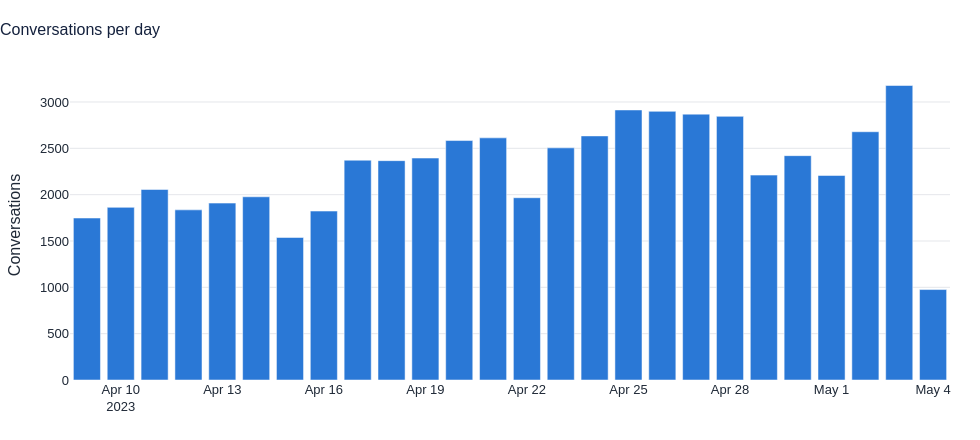

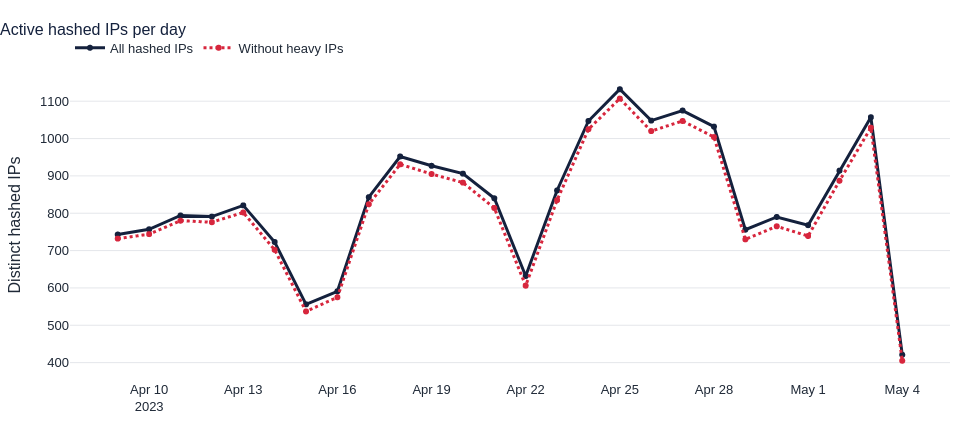

The logs cover 26 days. The average day holds 2,284 conversations. The peak day is 2023-05-03 with 3,178. Heavy IPs add 19.1% of all conversations. In plain words: on an average day about 837 distinct users appear, and heavy IPs add 19% of the volume.

In [6]:
daily = sql("select * from gold_daily_activity")
fig = go.Figure(go.Bar(x=daily.event_date, y=daily.conversations, marker_color=BLUE))
style(fig, "Conversations per day", ytitle="Conversations").show()

fig = go.Figure()
fig.add_trace(go.Scatter(x=daily.event_date, y=daily.active_hashed_ips, name="All hashed IPs", mode="lines+markers", line=dict(color=NAVY, width=3)))
fig.add_trace(go.Scatter(x=daily.event_date, y=daily.active_hashed_ips_excl_heavy, name="Without heavy IPs", mode="lines+markers", line=dict(color=RED, width=3, dash="dot")))
style(fig, "Active hashed IPs per day", ytitle="Distinct hashed IPs").show()

peak = daily.loc[daily.conversations.idxmax()]
heavy_share = daily.heavy_ip_conversations.sum() / daily.conversations.sum()
md(f"The logs cover {len(daily)} days. The average day holds {n(daily.conversations.mean())} conversations. "
   f"The peak day is {pd.Timestamp(peak.event_date).date()} with {n(peak.conversations)}. "
   f"Heavy IPs add {pct(heavy_share)} of all conversations. "
   f"In plain words: on an average day about {n(daily.active_hashed_ips.mean())} distinct users appear, and heavy IPs add {pct(heavy_share, 0)} of the volume.")

# 7. Model mix

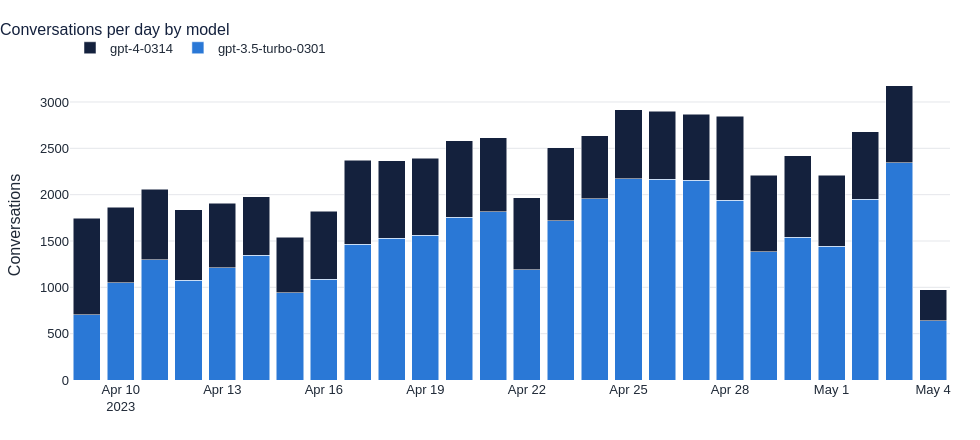

,model,conversations,share,avg_turns,median_turns,multi_turn_rate
0,gpt-3.5-turbo-0301,39447,0.664,3.355,2.000,0.584
1,gpt-4-0314,19939,0.336,1.938,1.000,0.375


The leading model is `gpt-3.5-turbo-0301` with 66.4% of conversations. In plain words: the top model carries 66% of the traffic, so product metrics follow that model closely.

In [7]:
mix = sql("select * from gold_model_mix_daily")
fig = go.Figure()
palette = [BLUE, NAVY, GREY, RED, "#EB6834", "#0F766E", "#7C3AED"]
for i, (m, g) in enumerate(mix.groupby("model")):
    fig.add_trace(go.Bar(x=g.event_date, y=g.conversations, name=m, marker_color=palette[i % len(palette)]))
fig.update_layout(barmode="stack")
style(fig, "Conversations per day by model", ytitle="Conversations").show()

model_summary = sql("""
select model, count(*) as conversations, count(*) * 1.0 / sum(count(*)) over () as share,
       avg(turn) as avg_turns, median(turn) as median_turns, avg((turn > 1)::int) as multi_turn_rate
from valid_conversations group by 1 order by 2 desc""")
display(model_summary)
top = model_summary.iloc[0]
md(f"The leading model is `{top.model}` with {pct(top.share)} of conversations. "
   f"In plain words: the top model carries {pct(top.share, 0)} of the traffic, so product metrics follow that model closely.")

# 8. Engagement depth

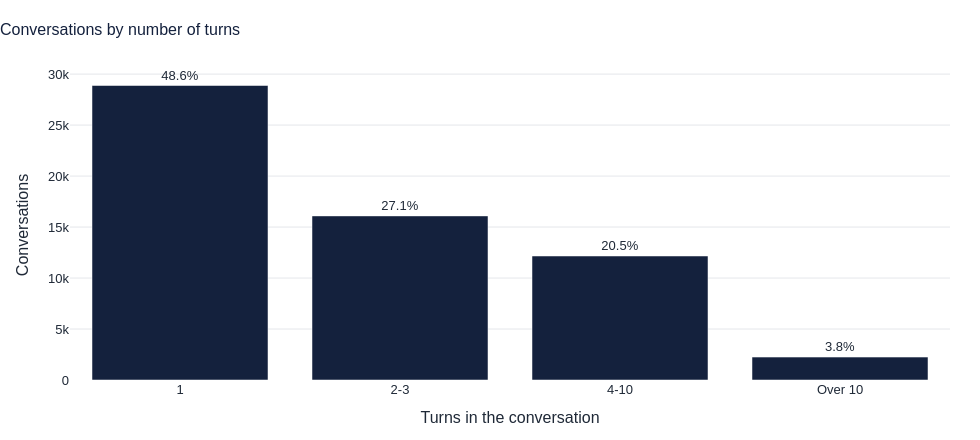

,mean_turns,median_turns,max_turns,multi_turn_rate
0,2.879,2.000,55,0.514


The mean conversation has 2.88 turns and the median has 2. 51.4% of conversations go past one turn. The longest has 55 turns. In plain words: 49% of conversations end after one exchange, and the rest continue.

In [8]:
turns = sql("select * from gold_turns_distribution")
fig = go.Figure(go.Bar(x=turns.turn_bucket, y=turns.conversations, marker_color=NAVY,
                       text=[pct(v / turns.conversations.sum()) for v in turns.conversations], textposition="outside"))
style(fig, "Conversations by number of turns", xtitle="Turns in the conversation", ytitle="Conversations").show()

stats = sql("select avg(turn) as mean_turns, median(turn) as median_turns, max(turn) as max_turns, avg((turn > 1)::int) as multi_turn_rate from valid_conversations")
display(stats)
s = stats.iloc[0]
md(f"The mean conversation has {s.mean_turns:.2f} turns and the median has {s.median_turns:.0f}. "
   f"{pct(s.multi_turn_rate)} of conversations go past one turn. The longest has {n(s.max_turns)} turns. "
   f"In plain words: {pct(1 - s.multi_turn_rate, 0)} of conversations end after one exchange, and the rest continue.")

# 9. Users: return rates and concentration

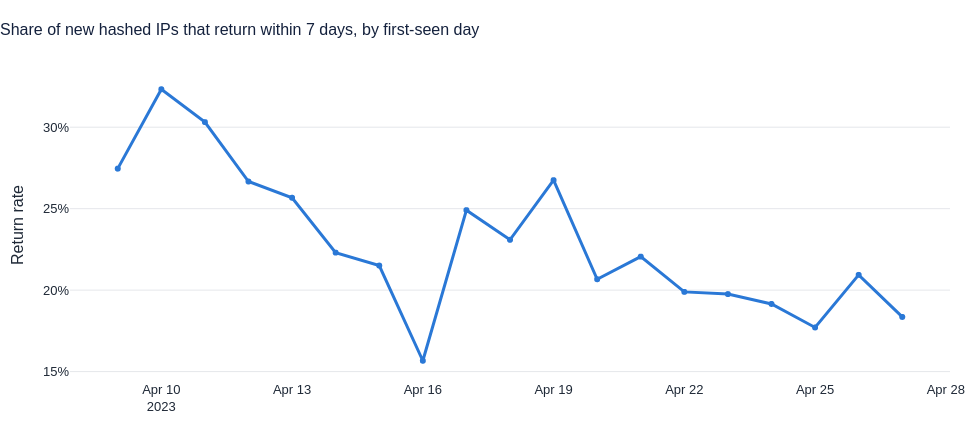

23.2% of new hashed IPs return within 7 days (2,380 of 10,277). In plain words: about 23 in 100 new users come back inside a week.

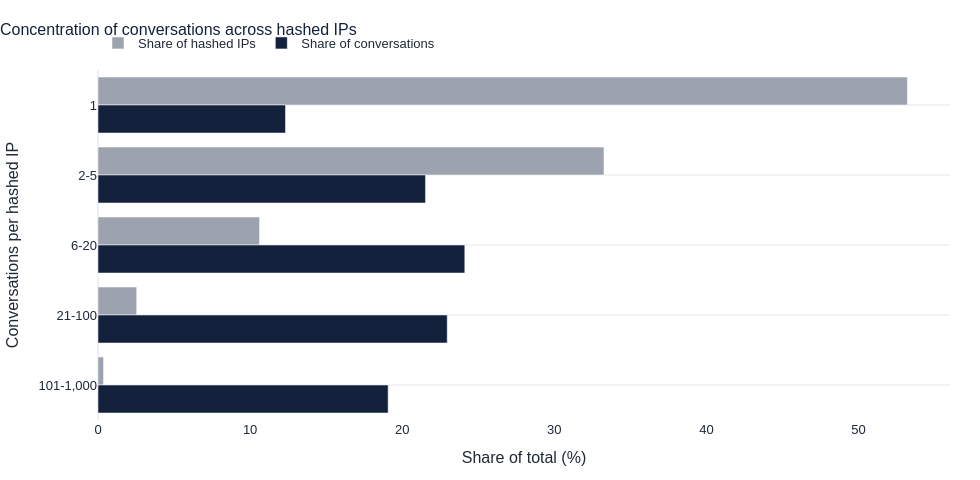

50 hashed IPs (0.36% of all) hold 19.1% of conversations. In plain words: 0.4% of users produce 19% of the traffic.

In [9]:
ret = sql("select * from gold_return_rates")
if len(ret):
    fig = go.Figure(go.Scatter(x=ret.cohort_date, y=ret.return_rate_7d, mode="lines+markers", line=dict(color=BLUE, width=3)))
    fig.update_yaxes(tickformat=".0%")
    style(fig, "Share of new hashed IPs that return within 7 days, by first-seen day", ytitle="Return rate").show()
    weighted = ret.returned_within_7_days.sum() / ret.new_hashed_ips.sum()
    md(f"{pct(weighted)} of new hashed IPs return within 7 days ({n(ret.returned_within_7_days.sum())} of {n(ret.new_hashed_ips.sum())}). "
       f"In plain words: about {round(weighted * 100)} in 100 new users come back inside a week.")

conc = sql("select * from gold_user_concentration")
fig = go.Figure()
fig.add_trace(go.Bar(y=conc.conversations_per_ip, x=100 * conc.hashed_ips / conc.hashed_ips.sum(), orientation="h", name="Share of hashed IPs", marker_color=GREY))
fig.add_trace(go.Bar(y=conc.conversations_per_ip, x=100 * conc.conversations / conc.conversations.sum(), orientation="h", name="Share of conversations", marker_color=NAVY))
fig.update_layout(barmode="group")
fig.update_yaxes(autorange="reversed")
style(fig, "Concentration of conversations across hashed IPs", xtitle="Share of total (%)", ytitle="Conversations per hashed IP", height=480).show()

heavy = sql(f"select count(*) filter (where is_heavy_ip) as heavy_ips, count(*) as ips, sum(conversations) filter (where is_heavy_ip) as heavy_convs, sum(conversations) as convs from dim_user_proxy").iloc[0]
md(f"{n(heavy.heavy_ips)} hashed IPs ({pct(heavy.heavy_ips / heavy.ips, 2)} of all) hold {pct(heavy.heavy_convs / heavy.convs)} of conversations. "
   f"In plain words: {pct(heavy.heavy_ips / heavy.ips, 1)} of users produce {pct(heavy.heavy_convs / heavy.convs, 0)} of the traffic.")

# 10. Language and country

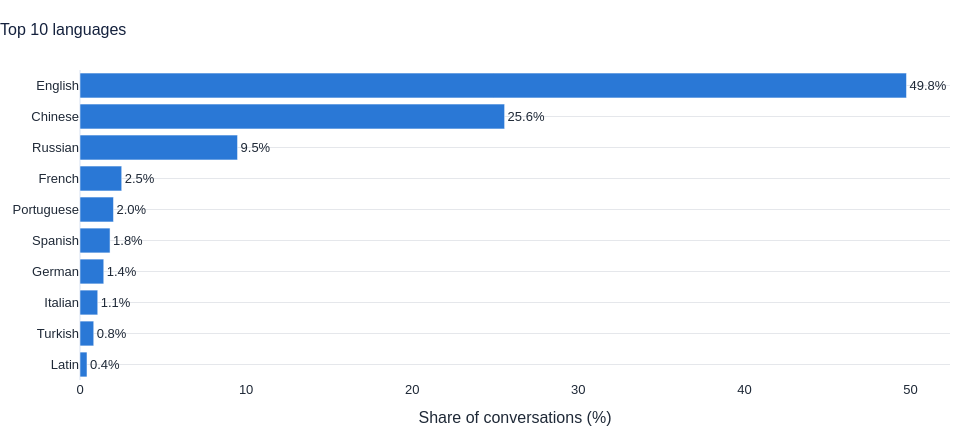

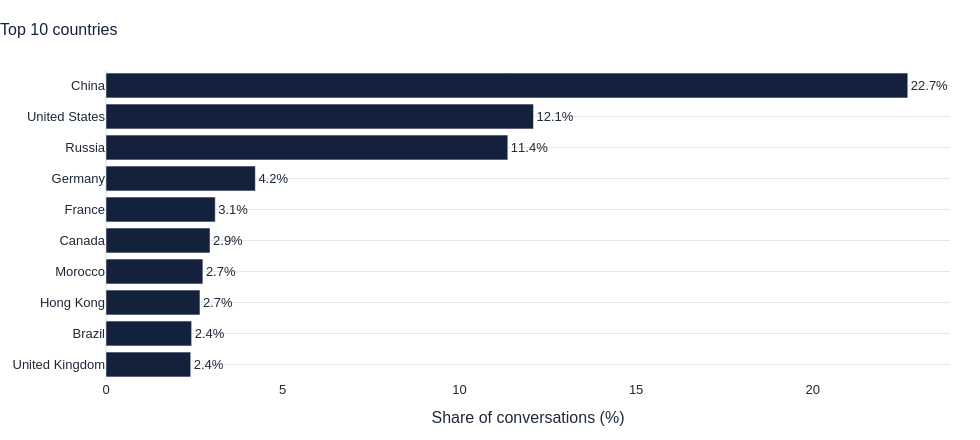

The logs hold 68 languages and 151 countries. `English` leads with 49.8%. `China` leads the countries with 22.7%. In plain words: the audience is international, and the top five countries hold 53% of the traffic.

In [10]:
lang = sql("select * from gold_language_mix limit 10")
fig = go.Figure(go.Bar(y=lang.language, x=100 * lang.share, orientation="h", marker_color=BLUE,
                       text=[pct(v) for v in lang.share], textposition="outside"))
fig.update_yaxes(autorange="reversed")
style(fig, "Top 10 languages", xtitle="Share of conversations (%)").show()

ctry = sql("select * from gold_country_mix limit 10")
fig = go.Figure(go.Bar(y=ctry.country, x=100 * ctry.share, orientation="h", marker_color=NAVY,
                       text=[pct(v) for v in ctry.share], textposition="outside"))
fig.update_yaxes(autorange="reversed")
style(fig, "Top 10 countries", xtitle="Share of conversations (%)").show()

n_lang = int(con.sql("select count(distinct language) from valid_conversations").fetchone()[0])
n_ctry = int(con.sql("select count(distinct country) from valid_conversations").fetchone()[0])
md(f"The logs hold {n_lang} languages and {n_ctry} countries. `{lang.language[0]}` leads with {pct(lang.share[0])}. "
   f"`{ctry.country[0]}` leads the countries with {pct(ctry.share[0])}. In plain words: the audience is international, and the top five countries hold {pct(ctry.share.head(5).sum(), 0)} of the traffic.")

# 11. Time of day pattern

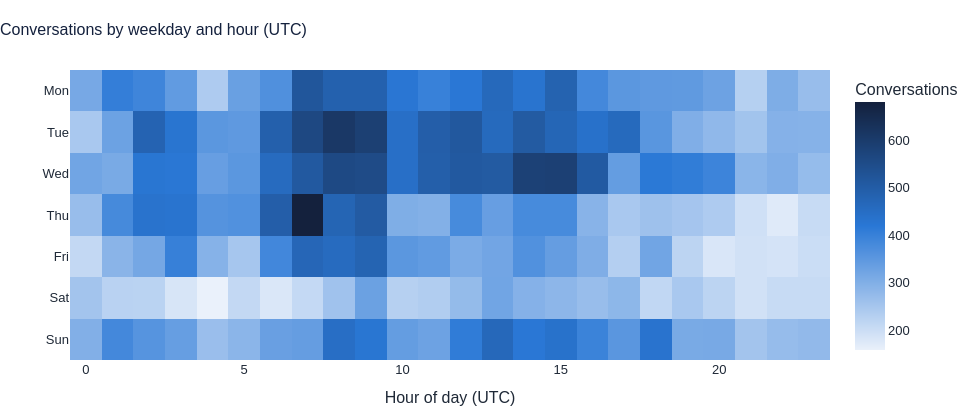

Activity peaks at 09:00 UTC and is lowest at 21:00 UTC. Wed is the busiest weekday. In plain words: usage follows a daily rhythm that product teams can plan around.

In [11]:
hourly = sql("select * from gold_hourly_pattern")
grid = hourly.pivot(index="iso_weekday", columns="hour_utc", values="conversations").reindex(index=range(1, 8), columns=range(24)).fillna(0)
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig = go.Figure(go.Heatmap(z=grid.values, x=list(range(24)), y=days, colorscale=[[0, "#EAF1FB"], [0.5, "#2A78D6"], [1, "#14213D"]],
                           colorbar=dict(title="Conversations")))
fig.update_yaxes(autorange="reversed")
style(fig, "Conversations by weekday and hour (UTC)", xtitle="Hour of day (UTC)", height=420).show()

by_hour = hourly.groupby("hour_utc").conversations.sum()
by_day = hourly.groupby("iso_weekday").conversations.sum()
md(f"Activity peaks at {by_hour.idxmax():02d}:00 UTC and is lowest at {by_hour.idxmin():02d}:00 UTC. "
   f"{days[by_day.idxmax() - 1]} is the busiest weekday. In plain words: usage follows a daily rhythm that product teams can plan around.")

# 12. Prompt length

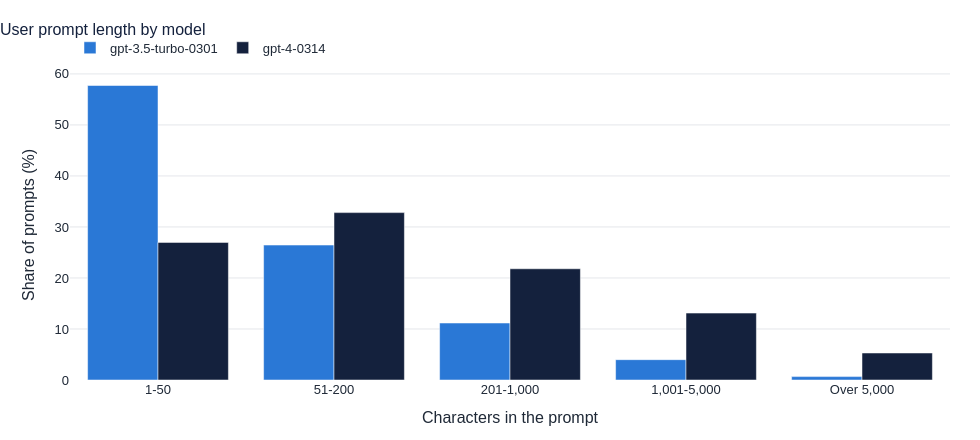

The median prompt has 49 characters and the mean has 416. The longest 5% of prompts exceed 1,905 characters. In plain words: the mean prompt is 8.5 times the median, so a tail of long prompts pulls the average up.

In [12]:
order = ["1-50", "51-200", "201-1,000", "1,001-5,000", "Over 5,000"]
length = sql("""
select model,
       case when char_len <= 50 then '1-50' when char_len <= 200 then '51-200' when char_len <= 1000 then '201-1,000'
            when char_len <= 5000 then '1,001-5,000' else 'Over 5,000' end as bucket,
       count(*) as prompts
from silver_utterances
where role = 'user' and not is_empty
group by 1, 2""")
share = length.pivot(index="bucket", columns="model", values="prompts").reindex(order).fillna(0)
share = share / share.sum()
fig = go.Figure()
for i, m in enumerate(share.columns):
    fig.add_trace(go.Bar(x=share.index, y=100 * share[m], name=m, marker_color=palette[i % len(palette)]))
fig.update_layout(barmode="group")
style(fig, "User prompt length by model", xtitle="Characters in the prompt", ytitle="Share of prompts (%)").show()

pl = sql("select avg(char_len) as mean_chars, median(char_len) as median_chars, quantile_cont(char_len, 0.95) as p95_chars, avg(word_count) as mean_words from silver_utterances where role = 'user' and not is_empty").iloc[0]
md(f"The median prompt has {pl.median_chars:.0f} characters and the mean has {pl.mean_chars:.0f}. The longest 5% of prompts exceed {pl.p95_chars:,.0f} characters. "
   f"In plain words: the mean prompt is {pl.mean_chars / max(pl.median_chars, 1):.1f} times the median, so a tail of long prompts pulls the average up.")

# 13. Moderation signals

In [13]:
moderation = sql("""
select model, count(*) as conversations,
       avg(moderation_flagged::int) as flagged_rate,
       avg(toxic::int) as toxic_rate,
       avg(max_toxicity) as mean_max_toxicity
from valid_conversations group by 1 order by 2 desc""")
display(moderation)
overall = float(con.sql("select avg(moderation_flagged::int) from valid_conversations").fetchone()[0])
if overall > 0:
    fig = go.Figure(go.Bar(x=moderation.model, y=100 * moderation.flagged_rate, marker_color=RED,
                           text=[pct(v, 2) for v in moderation.flagged_rate], textposition="outside"))
    style(fig, "Conversations flagged by the OpenAI moderation model", xtitle="Model", ytitle="Flagged conversations (%)").show()
    md(f"{pct(overall, 2)} of conversations carry at least one moderation flag. In plain words: flagged content is a small share of traffic, and the rate differs by model.")
else:
    md("No conversation carries a moderation flag. This matches the publisher's removal of toxic conversations before release. "
       "In plain words: the logs hold no flagged content, so safety rates need a source that keeps those conversations.")

,model,conversations,flagged_rate,toxic_rate,mean_max_toxicity
0,gpt-3.5-turbo-0301,39447,0.000,0.000,0.006
1,gpt-4-0314,19939,0.000,0.000,0.005


No conversation carries a moderation flag. This matches the publisher's removal of toxic conversations before release. In plain words: the logs hold no flagged content, so safety rates need a source that keeps those conversations.

# 14. Summary of findings

In [14]:
overall = sql("""
select count(*) as conversations, count(distinct hashed_ip) as hashed_ips,
       min(event_date) as first_day, max(event_date) as last_day,
       avg((turn > 1)::int) as multi_turn_rate
from valid_conversations""").iloc[0]
failing = quality[quality.status == "FAIL"].check.tolist()
lines = [
    f"- **Volume:** {n(overall.conversations)} usable conversations from {n(overall.hashed_ips)} hashed IPs between {pd.Timestamp(overall.first_day).date()} and {pd.Timestamp(overall.last_day).date()}.",
    f"- **Model mix:** `{model_summary.model.iloc[0]}` carries {pct(model_summary.share.iloc[0])} of conversations.",
    f"- **Engagement:** {pct(overall.multi_turn_rate)} of conversations have more than one turn.",
    f"- **Audience:** `{lang.language[0]}` is the top language ({pct(lang.share[0])}) and `{ctry.country[0]}` is the top country ({pct(ctry.share[0])}).",
    f"- **Concentration:** heavy IPs hold {pct(heavy.heavy_convs / heavy.convs)} of conversations.",
    f"- **Data quality:** {int((quality.status == 'PASS').sum())} of {len(quality)} checks pass" + (f"; failing checks: {', '.join(failing)}." if failing else "."),
]
md("\n".join(lines))

- **Volume:** 59,386 usable conversations from 13,757 hashed IPs between 2023-04-09 and 2023-05-04.
- **Model mix:** `gpt-3.5-turbo-0301` carries 66.4% of conversations.
- **Engagement:** 51.4% of conversations have more than one turn.
- **Audience:** `English` is the top language (49.8%) and `China` is the top country (22.7%).
- **Concentration:** heavy IPs hold 19.1% of conversations.
- **Data quality:** 11 of 11 checks pass.

# 15. Export

In [15]:
exported = []
for t in gold_tables + ["dim_user_proxy"]:
    path = OUT_DIR / f"{t}.parquet"
    con.execute(f"copy {t} to '{path}' (format parquet)")
    exported.append(dict(table=t, rows=int(con.sql(f"select count(*) from {t}").fetchone()[0]), size_kb=path.stat().st_size / 1024))
display(pd.DataFrame(exported))

,table,rows,size_kb
0,gold_daily_activity,26,2.040
1,gold_model_mix_daily,52,1.518
2,gold_turns_distribution,4,0.544
3,gold_language_mix,68,1.718
4,gold_country_mix,151,3.088
5,gold_hourly_pattern,168,1.400
6,gold_return_rates,19,1.020
7,gold_user_concentration,5,0.694
8,dim_user_proxy,13757,"1,081.932"
